# Где дешевле жить? Предсказание цен в Airbnb - учимся генерировать признаки и интерпретировать результаты модели

In [2]:
#YOUR CODE HERE
# Загружаем необходимые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
# Прочитем файл и сформируем датасет
df = pd.read_csv('AB_NYC_2019.csv')
df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [4]:
# Посмотрим информацию по каждому столбцу
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
# Уберём неинформативные столбцы и ещё раз посмотрим на информацию
df = df.drop(columns=['id', 'name', 'host_id', 'host_name', 'last_review', 'reviews_per_month'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   neighbourhood                   48895 non-null  object 
 2   latitude                        48895 non-null  float64
 3   longitude                       48895 non-null  float64
 4   room_type                       48895 non-null  object 
 5   price                           48895 non-null  int64  
 6   minimum_nights                  48895 non-null  int64  
 7   number_of_reviews               48895 non-null  int64  
 8   calculated_host_listings_count  48895 non-null  int64  
 9   availability_365                48895 non-null  int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 3.7+ MB


In [6]:
# Посмотрим количество уникальных значений в каждом столбце
df.nunique()

neighbourhood_group                   5
neighbourhood                       221
latitude                          19048
longitude                         14718
room_type                             3
price                               674
minimum_nights                      109
number_of_reviews                   394
calculated_host_listings_count       47
availability_365                    366
dtype: int64

In [7]:
# Посмотрим количество пропусков
df.isna().sum()

neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

In [8]:
# Посмотрим на статистику числовых признаков
df.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365
count,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000
mean,40.728949,-73.952170,152.720687,7.029962,23.274466,7.143982,112.781327
std,0.054530,0.046157,240.154170,20.510550,44.550582,32.952519,131.622289
min,40.499790,-74.244420,0.000000,1.000000,0.000000,1.000000,0.000000
25%,40.690100,-73.983070,69.000000,1.000000,1.000000,1.000000,0.000000
50%,40.723070,-73.955680,106.000000,3.000000,5.000000,1.000000,45.000000
75%,40.763115,-73.936275,175.000000,5.000000,24.000000,2.000000,227.000000
max,40.913060,-73.712990,10000.000000,1250.000000,629.000000,327.000000,365.000000


In [9]:
# Посмотрим на статистику по текстовым (object) признакам
df.describe(include=['object'])

,neighbourhood_group,neighbourhood,room_type
count,48895,48895,48895
unique,5,221,3
top,Manhattan,Williamsburg,Entire home/apt
freq,21661,3920,25409


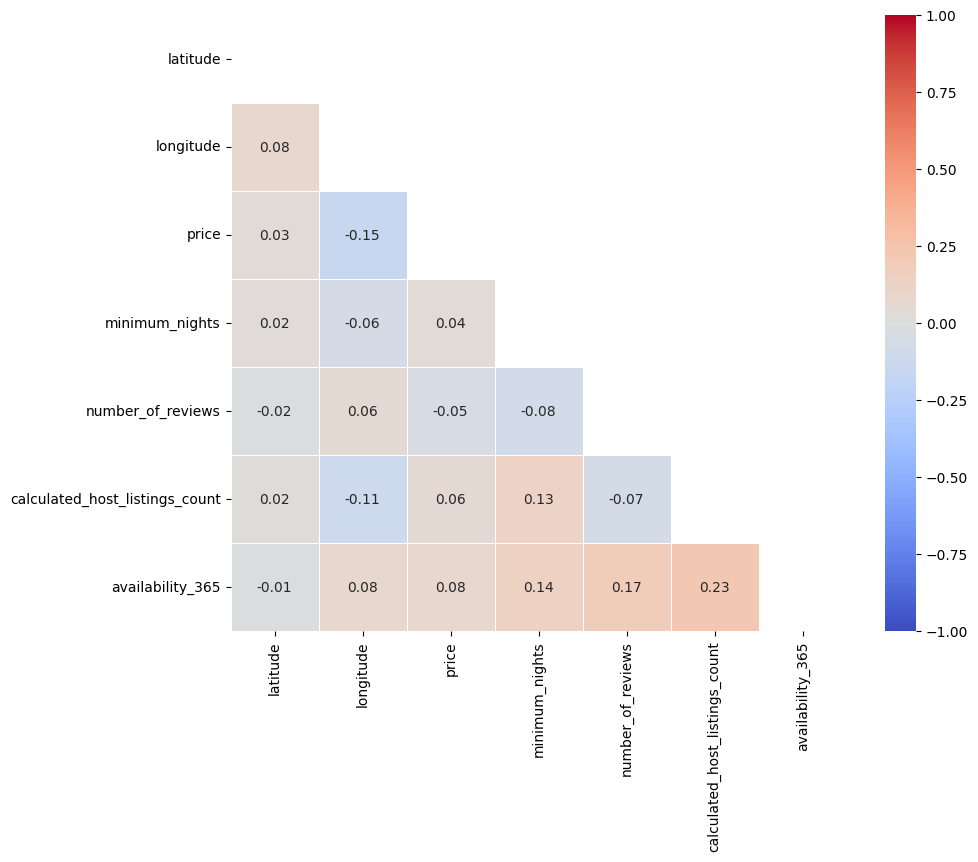

In [10]:
# Вычисляем матрицу корреляции для числовых признаков
corr = df.corr(numeric_only=True)

# Создаем маску для верхнего треугольника
mask = np.triu(np.ones_like(corr, dtype=bool))

# Настраиваем размер графика
plt.figure(figsize=(10, 8))

# Строим тепловую карту
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmax=1,
    vmin=-1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
)

# 5. Выводим график
plt.show()


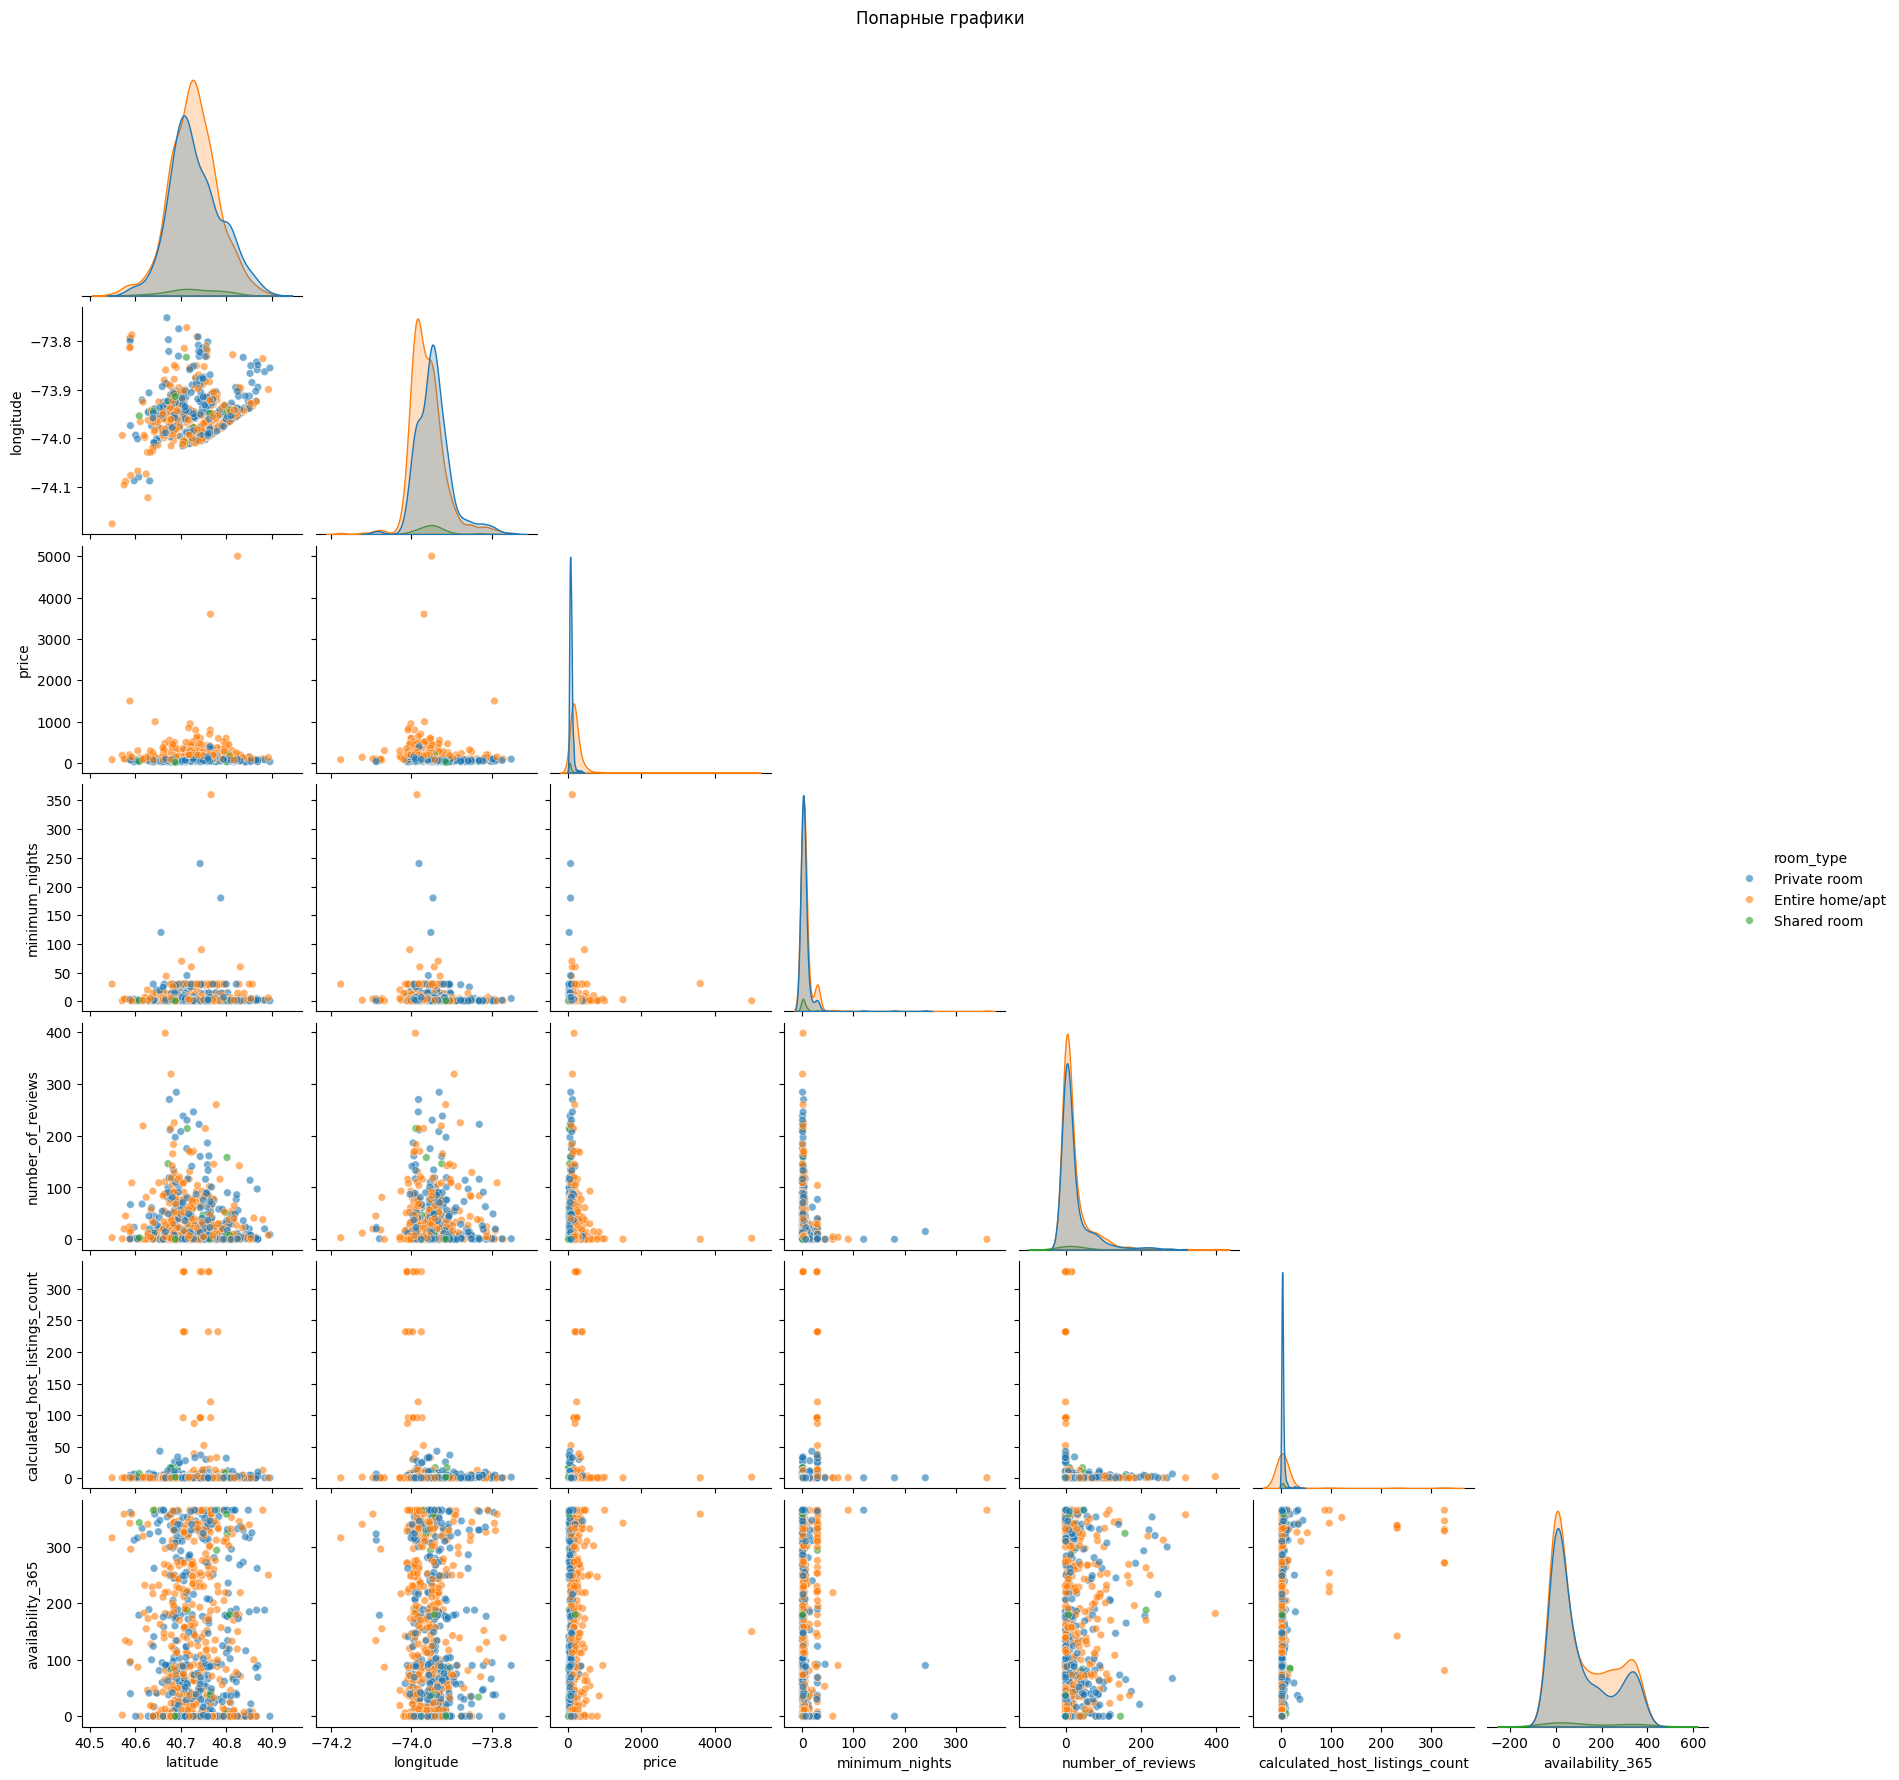

In [11]:
# Строим pairplot без верхнего треугольника
sns.pairplot(
    df.sample(1000, random_state=1101),
    corner=True,
    kind="scatter",
    diag_kind="kde",
    hue='room_type',
    plot_kws={"alpha": 0.6, "s": 30},
    )

plt.suptitle("Попарные графики", y=1.02, fontsize = 12)
plt.show() 

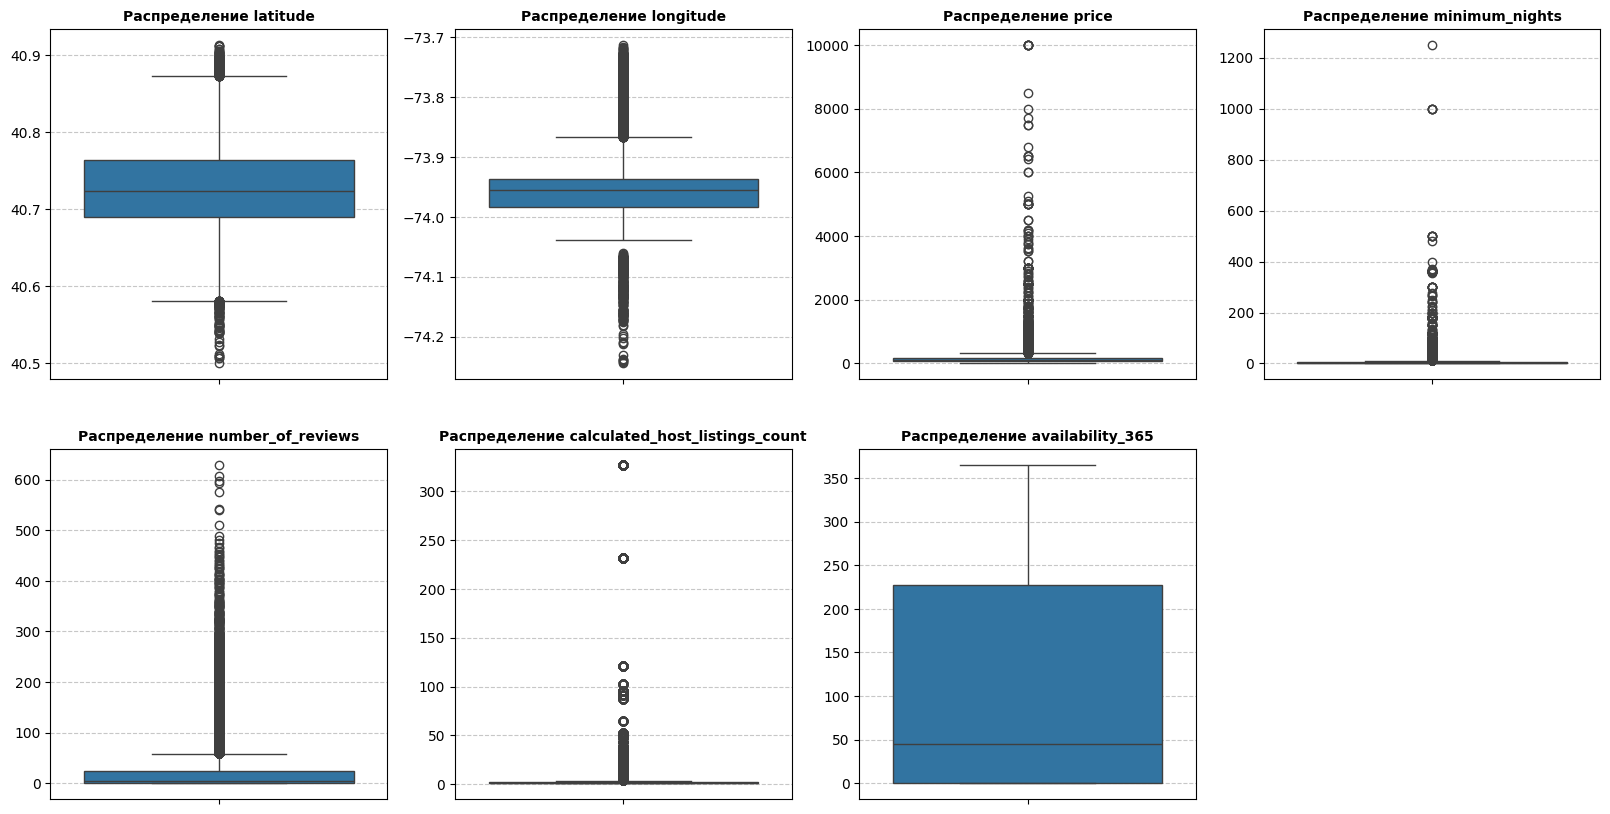

In [12]:
# Посмотрим насколько однородны данные.
# Задаем список из числовых признаков
features = df.select_dtypes(include=["number"]).columns.tolist()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

# Строим boxplot для каждого признака
for i, col in enumerate(features):
    sns.boxplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(f"Распределение {col}", fontsize=10, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].grid(axis="y", linestyle="--", alpha=0.7)

# Удаляем последний (8-й) пустой график, так как признаков всего 7
fig.delaxes(axes[-1])

plt.show()

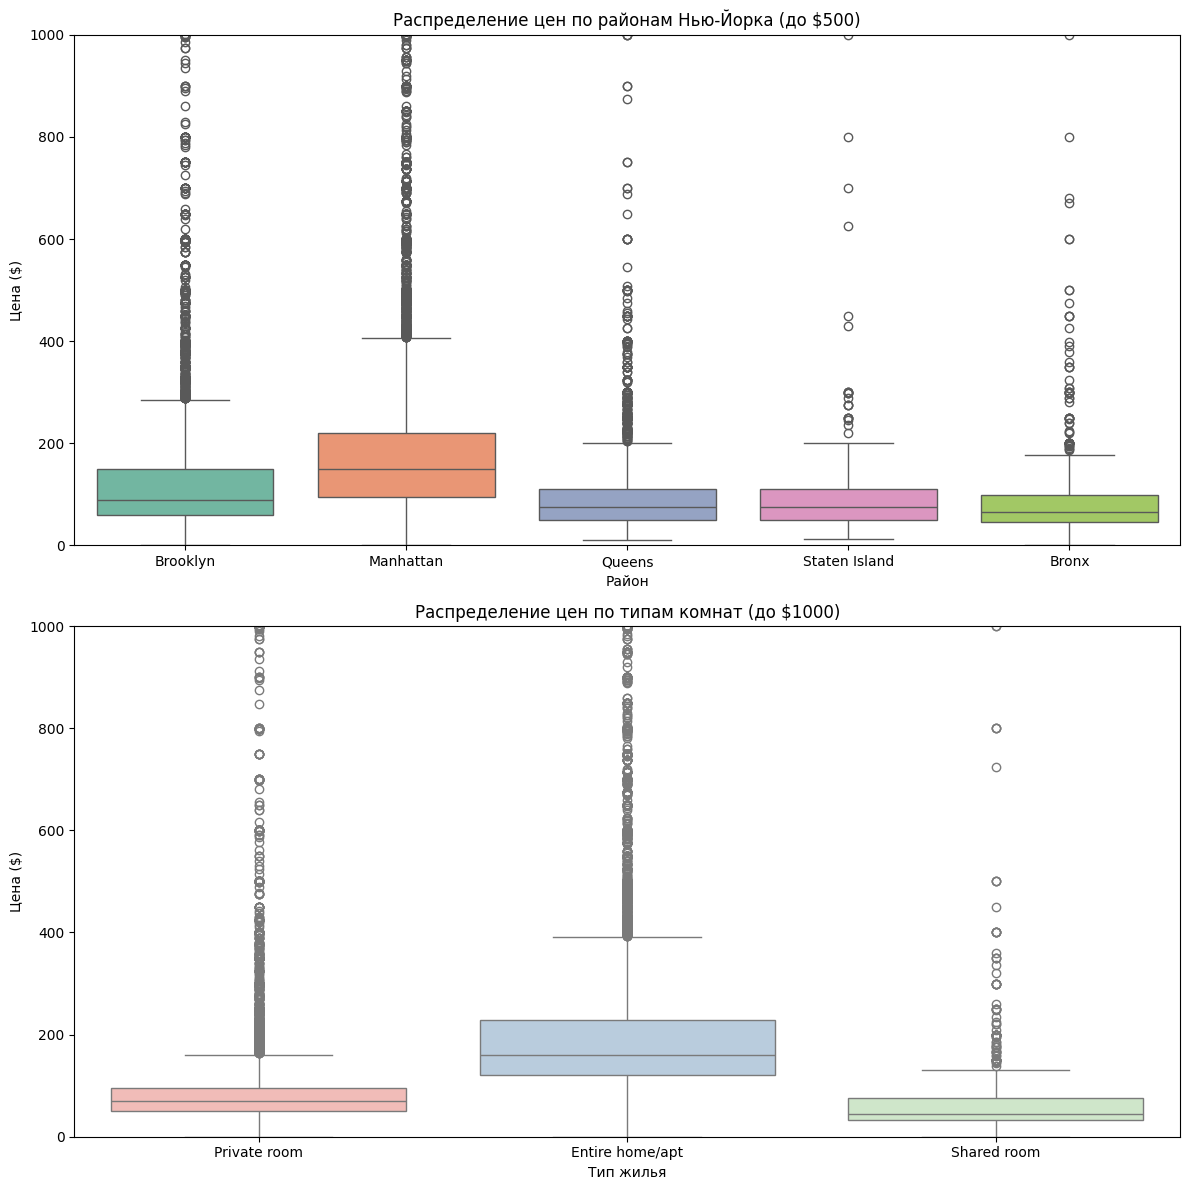

In [13]:
# Посмотрим, как распределяется наша целевая переменная (цена) 
# в зависимости от района города и типа жилья
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

# Цены по районам (ограничим цену до $1000 для наглядности)
sns.boxplot(
    data=df, x="neighbourhood_group", y="price", ax=axes[0], palette="Set2"
)
axes[0].set_title("Распределение цен по районам Нью-Йорка (до $500)")
axes[0].set_ylim(0, 1000)
axes[0].set_xlabel("Район")
axes[0].set_ylabel("Цена ($)")

# Цены по типам жилья
sns.boxplot(data=df, x="room_type", y="price", ax=axes[1], palette="Pastel1")
axes[1].set_title("Распределение цен по типам комнат (до $1000)")
axes[1].set_ylim(0, 1000)
axes[1].set_xlabel("Тип жилья")
axes[1].set_ylabel("Цена ($)")

plt.tight_layout()
plt.show()


In [14]:
# Выполним предобработку датасета

print(f"Размер датасета ДО очистки: {df.shape}")

# Фильтрация и удаление выбросов (Outliers)
# Цена (price): убираем элитный "хвост" выше 1000$
df = df[(df["price"] <= 1000)]

# Минимальные ночи (minimum_nights): ограничиваем 30 днями (краткосрочная аренда)
df = df[df["minimum_nights"] <= 30]

# Немного оптимизируем данные
# Переведём текстовые 'object' в специальный тип 'category',
# чтобы снизить потребление памяти и ускорит построение графиков
df["neighbourhood_group"] = df["neighbourhood_group"].astype("category")
df["room_type"] = df["room_type"].astype("category")
df["neighbourhood"] = df["neighbourhood"].astype("category")

# Проверим размер датасета
print(f"Размер датасета ПОСЛЕ очистки: {df.shape}")
print(
    f"Удалено аномальных строк: {48895 - df.shape[0]} ({((48895 - df.shape[0])/48895)*100:.2f}%)"
)


Размер датасета ДО очистки: (48895, 10)
Размер датасета ПОСЛЕ очистки: (47935, 10)
Удалено аномальных строк: 960 (1.96%)


In [15]:
# Создадим новый признак - расстояние от квартиры до центра Манхеттена.
# Находим медианные координаты Манхэттена из датасета
manhattan_data = df[df["neighbourhood_group"] == "Manhattan"]
manhattan_lat = manhattan_data["latitude"].median()
manhattan_lon = manhattan_data["longitude"].median()

# Считаем евклидово расстояние
df["euclidean_dist_to_manhattan"] = np.sqrt(
    (df["latitude"] - manhattan_lat) ** 2
    + (df["longitude"] - manhattan_lon) ** 2
)

In [16]:
# Посмотрим на статистику по числовым признакам
df.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,euclidean_dist_to_manhattan
count,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000
mean,40.728826,-73.951875,141.282403,5.576426,23.542985,7.164410,111.436320,0.070227
std,0.054590,0.046299,116.871854,8.196302,44.791153,33.122006,131.060301,0.045138
min,40.499790,-74.244420,0.000000,1.000000,0.000000,1.000000,0.000000,0.000392
25%,40.689940,-73.982850,69.000000,1.000000,1.000000,1.000000,0.000000,0.037988
50%,40.722860,-73.955510,105.000000,2.000000,5.000000,1.000000,43.000000,0.063221
75%,40.763050,-73.935845,175.000000,5.000000,24.000000,2.000000,223.000000,0.091506
max,40.913060,-73.712990,1000.000000,30.000000,629.000000,327.000000,365.000000,0.368894


In [17]:
# Посмотрим на статистику по текстовым (category) признакам
df.describe(include=['category'])

,neighbourhood_group,neighbourhood,room_type
count,47935,47935,47935
unique,5,221,3
top,Manhattan,Williamsburg,Entire home/apt
freq,21082,3857,24728


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47935 entries, 0 to 48894
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   neighbourhood_group             47935 non-null  category
 1   neighbourhood                   47935 non-null  category
 2   latitude                        47935 non-null  float64 
 3   longitude                       47935 non-null  float64 
 4   room_type                       47935 non-null  category
 5   price                           47935 non-null  int64   
 6   minimum_nights                  47935 non-null  int64   
 7   number_of_reviews               47935 non-null  int64   
 8   calculated_host_listings_count  47935 non-null  int64   
 9   availability_365                47935 non-null  int64   
 10  euclidean_dist_to_manhattan     47935 non-null  float64 
dtypes: category(3), float64(3), int64(5)
memory usage: 3.5 MB


In [21]:
# Выполним кодирование категориальных признаков

from sklearn.preprocessing import OneHotEncoder
from category_encoders import TargetEncoder

# Target Encoding (столбец neighbourhood)
# Разделяем на признак и целевую переменную
X1 = df[["neighbourhood"]]
X2 = df[["neighbourhood_group", "room_type"]]
y = df["price"].astype(float)

te = TargetEncoder(smoothing=10)
X_encoded_array = te.fit_transform(X1, y)
X_encoded = pd.DataFrame(
    X_encoded_array, 
    columns=te.get_feature_names_out(), 
    index=X1.index
)

# One-Hot Encoding (столбцы neighbourhood_group, room_type)
ohe = OneHotEncoder(sparse_output=False, drop="first")
ohe_features = ohe.fit_transform(X2)

# Создаем датафрейм из OHE-признаков
ohe_df = pd.DataFrame(
    ohe_features, 
    columns=ohe.get_feature_names_out(), 
    index=X2.index
)

# Удаляем из датасета категориальные столбцы
df_no_category = df.drop(columns=["neighbourhood_group", "room_type", "neighbourhood"])

# Собираем финальный датасет
df_final = pd.concat([df_no_category, ohe_df, X_encoded], axis=1)

print("Финальный размер матрицы признаков X:", df_final.shape)
print("Размер целевой переменной price:", y.shape)
df_final.head()


Финальный размер матрицы признаков X: (47935, 15)
Размер целевой переменной price: (47935,)


,latitude,longitude,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,euclidean_dist_to_manhattan,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room,neighbourhood
0,40.64749,-73.97237,149,1,9,6,365,0.113785,1.0,0.0,0.0,0.0,1.0,0.0,93.063595
1,40.75362,-73.98377,225,1,45,2,355,0.008129,0.0,1.0,0.0,0.0,0.0,0.0,266.583001
2,40.80902,-73.94190,150,3,0,1,365,0.061521,0.0,1.0,0.0,0.0,1.0,0.0,113.805598
3,40.68514,-73.95976,89,1,270,1,194,0.078600,1.0,0.0,0.0,0.0,0.0,0.0,149.953901
4,40.79851,-73.94399,80,10,9,1,0,0.052244,0.0,1.0,0.0,0.0,0.0,0.0,120.762035


In [23]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 47935 entries, 0 to 48894
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           47935 non-null  float64
 1   longitude                          47935 non-null  float64
 2   price                              47935 non-null  int64  
 3   minimum_nights                     47935 non-null  int64  
 4   number_of_reviews                  47935 non-null  int64  
 5   calculated_host_listings_count     47935 non-null  int64  
 6   availability_365                   47935 non-null  int64  
 7   euclidean_dist_to_manhattan        47935 non-null  float64
 8   neighbourhood_group_Brooklyn       47935 non-null  float64
 9   neighbourhood_group_Manhattan      47935 non-null  float64
 10  neighbourhood_group_Queens         47935 non-null  float64
 11  neighbourhood_group_Staten Island  47935 non-null  float64


In [24]:
df_final.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,calculated_host_listings_count,availability_365,euclidean_dist_to_manhattan,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room,neighbourhood
count,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000,47935.000000
mean,40.728826,-73.951875,141.282403,5.576426,23.542985,7.164410,111.436320,0.070227,0.413164,0.439804,0.116908,0.007656,0.460332,0.023803,141.924131
std,0.054590,0.046299,116.871854,8.196302,44.791153,33.122006,131.060301,0.045138,0.492407,0.496368,0.321314,0.087165,0.498429,0.152437,51.383074
min,40.499790,-74.244420,0.000000,1.000000,0.000000,1.000000,0.000000,0.000392,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,60.167747
25%,40.689940,-73.982850,69.000000,1.000000,1.000000,1.000000,0.000000,0.037988,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,101.347234
50%,40.722860,-73.955510,105.000000,2.000000,5.000000,1.000000,43.000000,0.063221,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,135.839205
75%,40.763050,-73.935845,175.000000,5.000000,24.000000,2.000000,223.000000,0.091506,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,174.063841
max,40.913060,-73.712990,1000.000000,30.000000,629.000000,327.000000,365.000000,0.368894,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,330.585260


In [25]:
# Выполним нормирование 2-мя способами и получим 2 набора для дальнейшей работы

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

# Выделяем целевую переменную и признаки
X = df_final.drop(columns=["price"])
y = df_final["price"]

# Разделяем на трейн и тест (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1101
)

# Нормировка StandardScaler
scaler_std = StandardScaler()
X_train_std = pd.DataFrame(
    scaler_std.fit_transform(X_train), columns=X_train.columns
)
X_test_std = pd.DataFrame(
    scaler_std.transform(X_test), columns=X_test.columns
)

# Нормировка RobustScaler
scaler_robust = RobustScaler()
X_train_robust = pd.DataFrame(
    scaler_robust.fit_transform(X_train), columns=X_train.columns
)
X_test_robust = pd.DataFrame(
    scaler_robust.transform(X_test), columns=X_test.columns
)

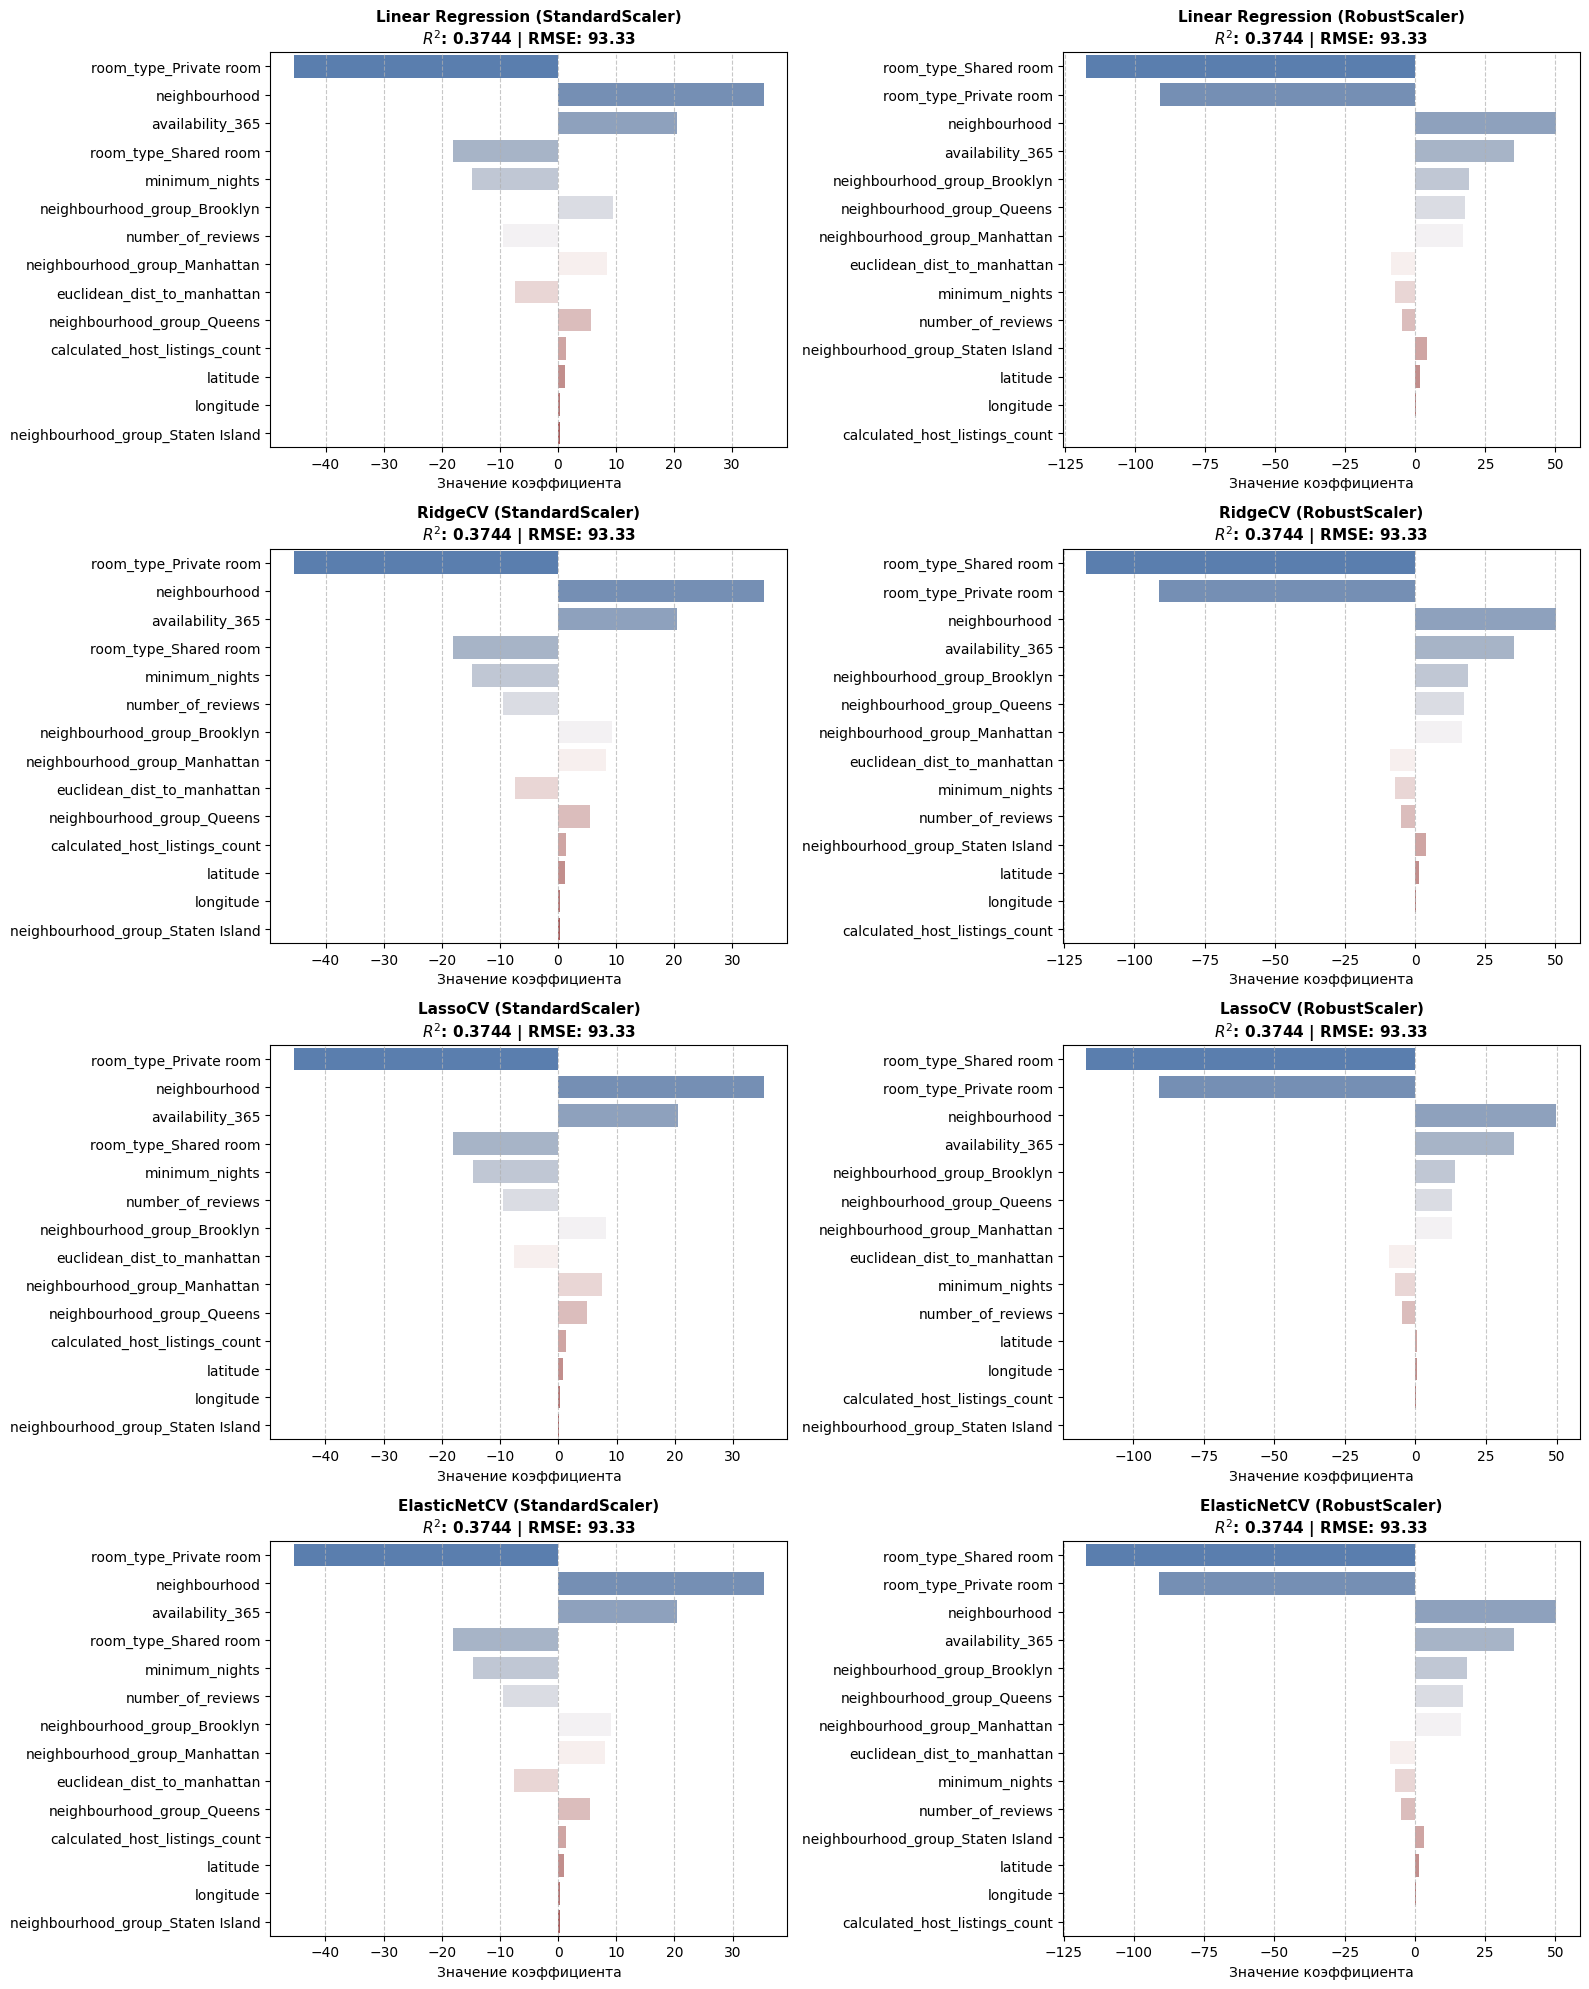


Сводная таблица качества моделей:


,Scaler,Model,R2 Score,RMSE
6,RobustScaler,LassoCV,0.374427,93.331728
2,StandardScaler,LassoCV,0.374420,93.332204
4,RobustScaler,Linear Regression,0.374419,93.332280
0,StandardScaler,Linear Regression,0.374419,93.332280
5,RobustScaler,RidgeCV,0.374417,93.332456
1,StandardScaler,RidgeCV,0.374416,93.332522
7,RobustScaler,ElasticNetCV,0.374415,93.332570
3,StandardScaler,ElasticNetCV,0.374415,93.332618


In [ ]:
# Построим модели простой линейной регрессии, RidgeCV, LassoCV и ElasticNetCV.

from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score

# Создадим списки для итераций по наборам данных и моделям
datasets = {
    "StandardScaler": (X_train_std, X_test_std), 
    "RobustScaler": (X_train_robust, X_test_robust)
}

models = {
    "Linear Regression": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=np.logspace(-3, 3, 10)),
    "LassoCV": LassoCV(alphas=np.logspace(-3, 3, 10), random_state=1101),
    "ElasticNetCV": ElasticNetCV(alphas=np.logspace(-3, 3, 10), l1_ratio=[0.1, 0.5, 0.7, 0.9], random_state=1101),
}

# Словарь для сохранения метрик
results_metrics = []

# Настройка графиков важности признаков
fig, axes = plt.subplots(4, 2, figsize=(16, 20), sharey=False)
plt.subplots_adjust(hspace=0.5, wspace=0.3)

# Цикл по двум типам нормировки
for col_idx, (scaler_name, (X_tr, X_te)) in enumerate(datasets.items()):

    # Цикл по моделям
    for row_idx, (model_name, model) in enumerate(models.items()):
        # Обучение модели
        model.fit(X_tr, y_train)

        # Предсказание и оценка качества
        y_pred = model.predict(X_te)
        r2 = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        # Сохраняем метрики в общую таблицу
        results_metrics.append(
            {"Scaler": scaler_name, "Model": model_name, "R2 Score": r2, "RMSE": rmse}
        )

        # Извлекаем важность признаков (коэффициентов)
        coefs = model.coef_
        importance_df = pd.DataFrame(
            {"Feature": X_tr.columns, "Coefficient": coefs, "Abs_Coefficient": np.abs(coefs)}
        ).sort_values(by="Abs_Coefficient", ascending=False)

        # Визуализация важности признаков (Коэффициентов)
        ax = axes[row_idx, col_idx]
        sns.barplot(
            data=importance_df,
            x="Coefficient",
            y="Feature",
            ax=ax,
            palette="vlag" if (importance_df["Coefficient"].min() < 0) else "Blues_r",
        )

        ax.set_title(
            f"{model_name} ({scaler_name})\n$R^2$: {r2:.4f} | RMSE: {rmse:.2f}",
            fontsize=11,
            fontweight="bold",
        )
        ax.set_xlabel("Значение коэффициента")
        ax.set_ylabel("")
        ax.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# Вывод сводной таблицы метрик качества
df_metrics = pd.DataFrame(results_metrics)
print("\nСводная таблица качества моделей:")
display(df_metrics.sort_values(by="R2 Score", ascending=False))


#### Краткий анализ результатов.  
* Самыми значимыми признаками для цены на жильё являются его тип и исторический район.  
* Все модели, вне зависимости от типа нормировки, показали практически одинаковые результаты.  
* Если в представленных данных и есть какие-то зависимости цены от имеющихся признаков, то они нелинейны, т.е. для их выявления нужны другие модели.